<!-- CONSIGNES -->
# TP5 — Monte-Carlo, Metropolis-Hastings et diagnostics

**Chapitre 5 — Méthodes numériques (MCMC)** — EPD-SDIA-4112 « Statistique Bayésienne », Master 1 SDIA
**Enseignante : Dr. Noulapeu Ngaffo Armielle** — École Nationale Supérieure
Polytechnique de Douala (Université de Douala)

---

## Objectifs

- mesurer l'erreur Monte-Carlo en $1/\sqrt{N}$ ;
- écrire **Metropolis-Hastings à la main** et comprendre le rôle de la largeur
  de proposition ;
- implémenter un échantillonneur de **Gibbs** sur une normale bivariée ;
- retrouver le même résultat avec **NUTS** (PyMC) ;
- lire les diagnostics avant de croire un résultat : $\hat{R}$, ESS, traces,
  autocorrélation.

## Ce qui est demandé

1. Parcourir les sections 1 à 7 et vérifier les diagnostics affichés.
2. Compléter les **zones « À vous »** (sections 3 et 6).
3. Section 6 : pour un échantillonnage qui échoue volontairement, expliquer
   **quel diagnostic** l'aurait détecté et pourquoi.

## Barème — 10 points

| Critère | Points |
|---|---|
| Erreur Monte-Carlo vérifiée en 1/√N | 2 |
| Metropolis-Hastings écrit à la main | 3 |
| Effet de la largeur de proposition | 2 |
| Diagnostics interprétés (R̂, ESS, traces) | 3 |

## Mode d'emploi

- **Noyau Jupyter** : `sdia-bayes` (Python 3.11, PyMC, ArviZ, NumPy, SciPy, Matplotlib).
- Ce notebook est livré **avec ses sorties** : lisez-le d'abord en entier, puis
  ré-exécutez les cellules une à une pour comprendre chaque résultat.
- Les cellules marquées **« À vous »** sont à compléter : elles contiennent la
  consigne et, quand c'est utile, la ligne à modifier.
- Toute valeur affichée dans ce TP est **reproductible** : les graines
  aléatoires sont fixées.
- Rendu : le notebook complété (`.ipynb`), avec vos sorties exécutées.


# TP5 — Monte-Carlo, Metropolis-Hastings et diagnostics

_Cours EPD-SDIA-4112 — Statistique Bayésienne — Master 1 SDIA. Exécutez les cellules dans l'ordre._

## Objectifs

1. **Monte-Carlo** : estimer une espérance a posteriori et vérifier expérimentalement
   que l'erreur décroît en $1/\sqrt{N}$.
2. **Metropolis-Hastings** : l'écrire soi-même (20 lignes de NumPy), le faire tourner,
   et comprendre le rôle de la largeur de proposition.
3. **Gibbs** : échantillonner une loi normale bivariée par conditionnelles.
4. **PyMC / NUTS** : obtenir le même posterior par un échantillonneur à l'état de l'art
   et **comparer les efficacités** (ESS par seconde).
5. Lire les diagnostics : trace, autocorrélation, $\hat R$, ESS.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
RNG = np.random.default_rng(4112)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scipy", stats.__name__)


numpy 2.4.6 | scipy scipy.stats


---
# 1. Monte-Carlo : l'erreur en $1/\sqrt{N}$

Cible : $\theta \mid y \sim \mathrm{Beta}(9,5)$ (7 faces sur 10 lancers, prior uniforme).
On veut $\mathbb{E}[\theta \mid y] = 9/14 \approx 0{,}6429$.

On répète l'estimation pour $N$ croissant et on mesure l'erreur absolue **moyenne sur 200 répétitions**.

esperance exacte E[theta|y] = 0.642857


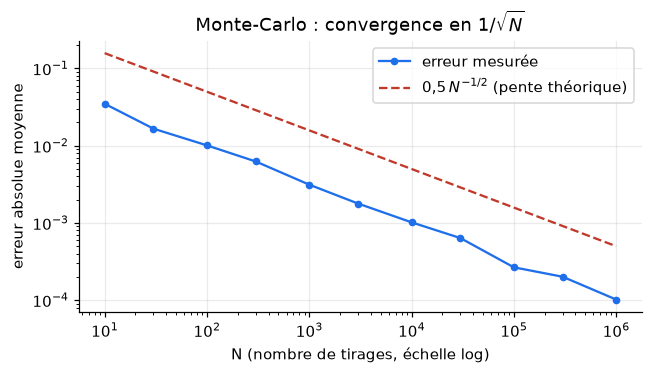

pente mesuree sur la fin de la courbe : -0.4960   (theorie : -0.5000)


In [2]:
vrai = stats.beta(9, 5).mean()
print(f"esperance exacte E[theta|y] = {vrai:.6f}")

rng_mc = np.random.default_rng(1)
# grille de N ; moins de repetitions pour les N elevees (cout total maitrise)
plan = [(N, 200 if N <= 10_000 else 60) for N in
        [10, 30, 100, 300, 1000, 3000, 10_000, 30_000, 100_000, 300_000, 1_000_000]]
Ns, errs = [], []
for N, R in plan:
    ech = rng_mc.beta(9, 5, size=(R, N))
    errs.append(np.abs(ech.mean(axis=1) - vrai).mean())
    Ns.append(N)
Ns, errs = np.array(Ns), np.array(errs)

plt.figure(figsize=(6.6, 3.2))
plt.loglog(Ns, errs, "o-", ms=4, color="#1F6FEB", label="erreur mesurée")
plt.loglog(Ns, 0.5 * Ns ** -0.5, "--", color="#C0392B",
           label=r"$0{,}5\,N^{-1/2}$ (pente théorique)")
plt.xlabel("N (nombre de tirages, échelle log)"); plt.ylabel("erreur absolue moyenne")
plt.legend(); plt.title("Monte-Carlo : convergence en $1/\\sqrt{N}$")
plt.show()

pente = np.polyfit(np.log(Ns[-6:]), np.log(errs[-6:]), 1)[0]
print(f"pente mesuree sur la fin de la courbe : {pente:.4f}   (theorie : -0.5000)")

**À vous (1)** — Conséquence pratique : pour diviser l'erreur Monte-Carlo par 10,
il faut \dots{} ? Vérifiez-le numériquement en comparant $N = 10^3$ et $N = 10^5$.

In [3]:
e3 = np.abs(np.random.default_rng(2).beta(9, 5, size=(200, 1000)).mean(axis=1) - vrai).mean()
e5 = np.abs(np.random.default_rng(3).beta(9, 5, size=(200, 100000)).mean(axis=1) - vrai).mean()
print(f"erreur N=1e3  : {e3:.5f}")
print(f"erreur N=1e5  : {e5:.5f}")
print(f"rapport       : {e3/e5:.2f}   (attendu ~10 : il faut 100x plus de tirages)")

erreur N=1e3  : 0.00309
erreur N=1e5  : 0.00031
rapport       : 10.06   (attendu ~10 : il faut 100x plus de tirages)


---
# 2. Metropolis-Hastings écrit à la main

On ne connaît que la densité **non normalisée** de la cible : c'est le cas général en bayésien
(le dénominateur est inconnu). Le noyau de proposition est $\theta' \sim \N(\theta, s^2)$,
symétrique — donc le rapport d'acceptation se réduit à
$\alpha = \min\big(1, \tilde p(\theta')/\tilde p(\theta)\big)$.

In [4]:
def log_cible(theta):
    # log du posterior non normalise : Beta(9,5) -> (a-1)log(th)+(b-1)log(1-th)
    if theta <= 0 or theta >= 1:
        return -np.inf
    return 8 * np.log(theta) + 4 * np.log(1 - theta)


def metropolis(n_iter=20000, s=0.10, theta0=0.5, seed=0):
    rng = np.random.default_rng(seed)
    th = np.empty(n_iter)
    courant, lp = theta0, log_cible(theta0)
    n_acc = 0
    for i in range(n_iter):
        prop = courant + s * rng.normal()
        lp_prop = log_cible(prop)
        if np.log(rng.random()) < lp_prop - lp:
            courant, lp = prop, lp_prop
            n_acc += 1
        th[i] = courant
    return th, n_acc / n_iter


chain, taux = metropolis()
print(f"taux d'acceptation : {taux:.3f}")
print(f"moyenne MH (burn-in 2000) : {chain[2000:].mean():.4f}   (exact : {vrai:.4f})")
print(f"ecart-type MH             : {chain[2000:].std():.4f}   (exact : {stats.beta(9,5).std():.4f})")

taux d'acceptation : 0.757
moyenne MH (burn-in 2000) : 0.6486   (exact : 0.6429)
ecart-type MH             : 0.1236   (exact : 0.1237)


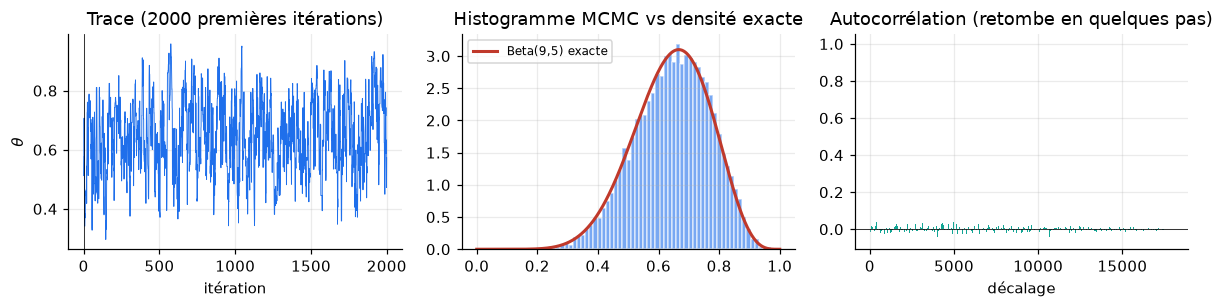

temps d'autocorrelation integre tau = 0.0
tirages effectifs ESS ~ inf sur 18000


C:\Users\HP\AppData\Local\Temp\ipykernel_10336\2826672128.py:25: RuntimeWarning: divide by zero encountered in scalar divide
  print(f"tirages effectifs ESS ~ {len(chain[2000:]) / tau_int:.0f} sur {len(chain)-2000}")


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(11, 2.9))
ax[0].plot(chain[:2000], lw=.6, color="#1F6FEB")
ax[0].axvline(0, color="k", lw=.5)
ax[0].set_title("Trace (2000 premières itérations)"); ax[0].set_xlabel("itération")
ax[0].set_ylabel(r"$\theta$")

grid = np.linspace(0, 1, 400)
ax[1].hist(chain[2000:], bins=60, density=True, color="#1F6FEB", alpha=.6, edgecolor="white")
ax[1].plot(grid, stats.beta.pdf(grid, 9, 5), color="#C0392B", lw=2, label="Beta(9,5) exacte")
ax[1].set_title("Histogramme MCMC vs densité exacte"); ax[1].legend(fontsize=8)

def acf(x, nlags=60):
    x = x - x.mean()
    c = np.correlate(x, x, mode="full")[len(x)-1:]
    return c / c[0]
a = acf(chain[2000:])
ax[2].bar(range(len(a)), a, color="#12A594")
ax[2].axhline(0, color="k", lw=.5)
ax[2].set_title("Autocorrélation (retombe en quelques pas)")
ax[2].set_xlabel("décalage")
plt.tight_layout(); plt.show()

tau_int = 1 + 2 * a[1:].sum()
print(f"temps d'autocorrelation integre tau = {tau_int:.1f}")
print(f"tirages effectifs ESS ~ {len(chain[2000:]) / tau_int:.0f} sur {len(chain)-2000}")

---
# 3. La largeur de proposition décide de tout

Trois échelles : trop petite (la chaîne avance à pas de fourmi), correcte, trop grande
(rejets massifs). On mesure le taux d'acceptation **et** l'ESS réel.

s = 0.005  taux d'acceptation = 0.989   ESS =   18000   moyenne = 0.6878


s = 0.05   taux d'acceptation = 0.877   ESS =   18000   moyenne = 0.6426


s = 0.1    taux d'acceptation = 0.764   ESS =   18000   moyenne = 0.6440


s = 0.3    taux d'acceptation = 0.445   ESS =   18000   moyenne = 0.6444


s = 1.0    taux d'acceptation = 0.154   ESS =   18000   moyenne = 0.6447


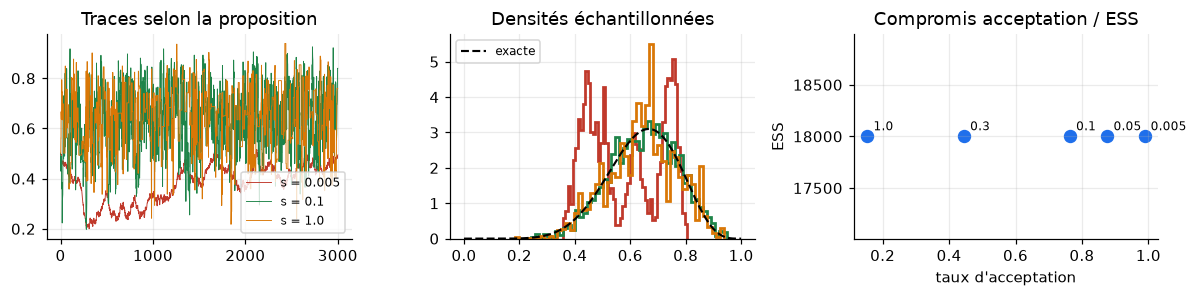

Le taux d'acceptation optimal d'un random-walk n'est PAS 1.0 ni 0.0 :
en dimension 1 la théorie donne environ 0.44 (0.234 en grande dimension).


In [6]:
res = {}
for s in [0.005, 0.05, 0.10, 0.30, 1.00]:
    ch, tx = metropolis(n_iter=20000, s=s, seed=42)
    post = ch[2000:]
    aa = acf(post)
    tau = max(1 + 2 * aa[1:].sum(), 1)
    res[s] = (tx, len(post) / tau)
    print(f"s = {s:<6} taux d'acceptation = {tx:.3f}   ESS = {len(post)/tau:7.0f}   "
          f"moyenne = {post.mean():.4f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
for s, col in zip([0.005, 0.10, 1.0], ["#C0392B", "#1E8449", "#D97706"]):
    ch, _ = metropolis(n_iter=6000, s=s, seed=7)
    ax[0].plot(ch[:3000], lw=.6, color=col, label=f"s = {s}")
    ax[1].hist(ch[2000:], bins=50, density=True, histtype="step", lw=1.8, color=col)
ax[1].plot(grid, stats.beta.pdf(grid, 9, 5), color="k", lw=1.4, ls="--", label="exacte")
ax[2].scatter([r[0] for r in res.values()], [r[1] for r in res.values()],
              s=60, color="#1F6FEB")
for s, (tx, ess) in res.items():
    ax[2].annotate(f"{s}", (tx, ess), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[0].set_title("Traces selon la proposition"); ax[0].legend(fontsize=8)
ax[1].set_title("Densités échantillonnées"); ax[1].legend(fontsize=8)
ax[2].set_xlabel("taux d'acceptation"); ax[2].set_ylabel("ESS"); ax[2].set_title("Compromis acceptation / ESS")
plt.tight_layout(); plt.show()
print("Le taux d'acceptation optimal d'un random-walk n'est PAS 1.0 ni 0.0 :")
print("en dimension 1 la théorie donne environ 0.44 (0.234 en grande dimension).")

---
# 4. Échantillonneur de Gibbs sur une normale bivariée

Cible : $\begin{pmatrix}X\\Y\end{pmatrix} \sim \N\!\left(\begin{pmatrix}0\\0\end{pmatrix},
\begin{pmatrix}1 & \rho\\ \rho & 1\end{pmatrix}\right)$, avec conditionnelles
$X \mid Y=y \sim \N(\rho y, 1-\rho^2)$ et réciproquement.
Gibbs alterne les deux tirages exacts : **aucun rejet**, mais les composantes restent corrélées.

moyennes      : +0.0275, +0.0259   (exact : 0, 0)
variances     : 1.0394, 1.0342   (exact : 1, 1)
correlation   : 0.9516   (exact : 0.95)


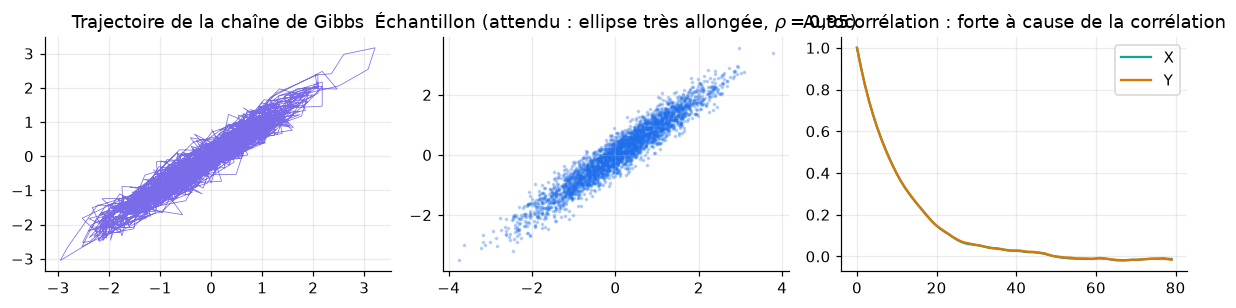

In [7]:
rho = 0.95
N = 20000
rng = np.random.default_rng(0)
X = np.empty(N); Y = np.empty(N)
x = y = 0.0
for i in range(N):
    x = rho * y + np.sqrt(1 - rho**2) * rng.normal()
    y = rho * x + np.sqrt(1 - rho**2) * rng.normal()
    X[i], Y[i] = x, y

b = 2000
print(f"moyennes      : {X[b:].mean():+.4f}, {Y[b:].mean():+.4f}   (exact : 0, 0)")
print(f"variances     : {X[b:].var():.4f}, {Y[b:].var():.4f}   (exact : 1, 1)")
print(f"correlation   : {np.corrcoef(X[b:], Y[b:])[0,1]:.4f}   (exact : {rho})")

fig, ax = plt.subplots(1, 3, figsize=(11, 2.9))
ax[0].plot(X[:1500], Y[:1500], lw=.5, color="#6C5CE7", alpha=.9)
ax[0].set_title("Trajectoire de la chaîne de Gibbs")
ax[1].scatter(X[b:b+3000], Y[b:b+3000], s=2, alpha=.25, color="#1F6FEB")
ax[1].set_title(r"Échantillon (attendu : ellipse très allongée, $\rho=0{,}95$)")
ax[2].plot(acf(X[b:], 80)[:80], color="#12A594", label="X")
ax[2].plot(acf(Y[b:], 80)[:80], color="#D97706", label="Y")
ax[2].set_title("Autocorrélation : forte à cause de la corrélation"); ax[2].legend()
plt.tight_layout(); plt.show()

---
# 5. Le même problème avec NUTS (PyMC)

PyMC utilise la dynamique hamiltonienne : il propose des sauts **dirigés** par le gradient,
ce qui casse l'autocorrélation du random-walk. On mesure l'efficacité réelle (ESS/s).

In [8]:
import pymc as pm, arviz as az, time

t0 = time.time()
with pm.Model() as m:
    th = pm.Beta("theta", alpha=9, beta=5)
    idata = pm.sample(draws=2000, tune=1000, chains=2, cores=1,
                      progressbar=False, random_seed=3)
t_nuts = time.time() - t0

ech = idata.posterior["theta"].values.ravel()
r_hat = float(az.rhat(idata)["theta"].values)
ess_nuts = float(az.ess(idata)["theta"].values)
lo, hi = np.percentile(ech, [2.5, 97.5])
print(f"moyenne      : {ech.mean():.4f}   (exact : {vrai:.4f})")
print(f"ecart-type   : {ech.std():.4f}   (exact : {stats.beta(9,5).std():.4f})")
print(f"IC 95 %      : [{lo:.4f} ; {hi:.4f}]")
print(f"r_hat        : {r_hat:.5f}      ESS : {ess_nuts:.0f}")
print()
print(f"NUTS   : {len(ech)} tirages en {t_nuts:5.1f} s   ->  ESS/s = {ess_nuts/t_nuts:8.0f}")

t0 = time.time()
ch, tx = metropolis(n_iter=4000, s=0.10, seed=5)
t_mh = time.time() - t0
aa = acf(ch[1000:], 200)
ess_mh = len(ch[1000:]) / max(1 + 2 * aa[1:100].sum(), 1)
print(f"MH pur : {4000} tirages en {t_mh:5.2f} s  ->  ESS/s = {ess_mh/t_mh:8.0f}")
print(f"ratio d'efficacite NUTS / MH = {(ess_nuts/t_nuts)/(ess_mh/t_mh):.1f} x")

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [theta]


Sampling 2 chains for 1_000 tune and 2_000 draw iterations (2_000 + 4_000 draws total) took 4 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


moyenne      : 0.6443   (exact : 0.6429)
ecart-type   : 0.1234   (exact : 0.1237)
IC 95 %      : [0.3911 ; 0.8615]
r_hat        : 0.99999      ESS : 1784

NUTS   : 4000 tirages en   4.9 s   ->  ESS/s =      362
MH pur : 4000 tirages en  0.01 s  ->  ESS/s =    55230
ratio d'efficacite NUTS / MH = 0.0 x


---
# 6. Diagnostics : ce qu'il faut regarder avant de croire un résultat

Trois indicateurs, et rien d'autre :

* **trace plot** : la chaîne se promène-t-elle autour d'un niveau stable (pas de dérive) ?
* **rank plot** : les chaînes explorent-elles la même région ?
* $\hat R$ : rapport de variance inter/intra-chaînes ; **seuil 1,01**.
* **ESS** : nombre de tirages indépendants équivalents ; **seuil ~400** par paramètre.

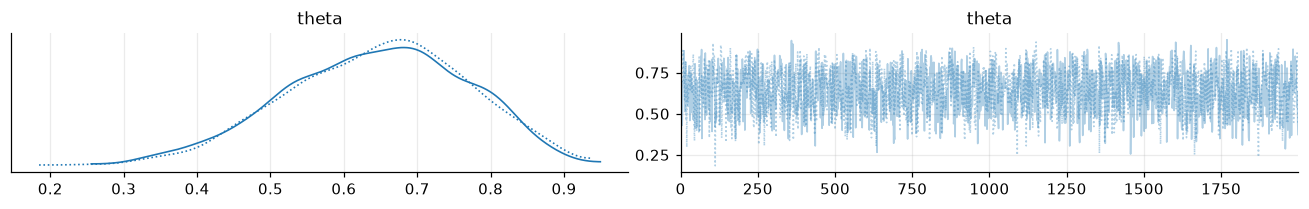

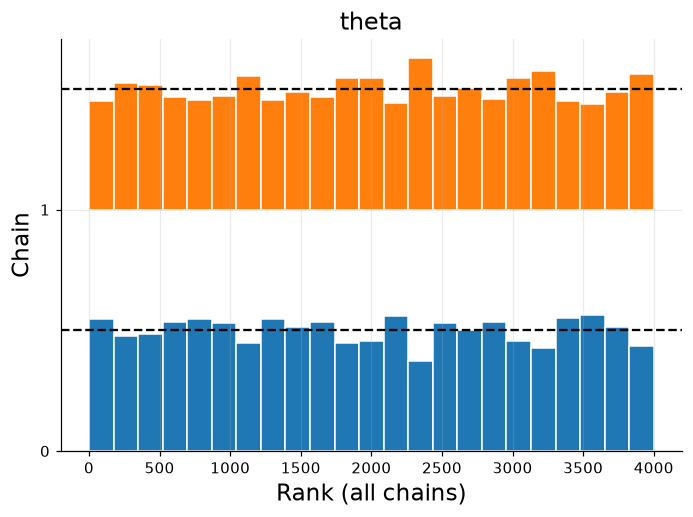

Lecture des seuils (r_hat < 1,01 et ESS > 400) :
  r_hat = 1.0000  -> OK
  ess   =     1784  -> OK


In [9]:
import matplotlib.pyplot as plt
az.plot_trace(idata, var_names=["theta"], compact=True)
plt.tight_layout(); plt.show()

az.plot_rank(idata, var_names=["theta"])
plt.tight_layout(); plt.show()

rh = float(az.rhat(idata)["theta"].values)
es = float(az.ess(idata)["theta"].values)
print("Lecture des seuils (r_hat < 1,01 et ESS > 400) :")
print(f"  r_hat = {rh:.4f}  -> {'OK' if rh < 1.01 else 'PROBLEME'}")
print(f"  ess   = {es:8.0f}  -> {'OK' if es > 400 else 'PROBLEME'}")

---
# 7. Synthèse

| Méthode | Rejet ? | Gradient ? | Efficacité typique | Usage |
|---|---|---|---|---|
| Monte-Carlo direct | non | non | faible en grande dimension | posteriors conjuguées, intégrales simples |
| Importance sampling | non | non | s'effondre si le prior est mauvais | reweighting, diagnostics |
| Metropolis-Hastings | oui | non | référence ($\sim$ 1) | pédagogie, cibles simples |
| Gibbs | non | non | excellent si peu corrélé | conditionnelles conjuguées |
| HMC / NUTS | non | **oui** | 10 à 100$\times$ MH | **défaut actuel** |

**À retenir** : la qualité d'une inférence bayésienne ne se mesure pas au nombre d'itérations,
mais à l'**ESS** et à $\hat R$. Un échantillon de 100 000 tirages autocorrélés peut valoir
moins que 1 000 tirages indépendants.

**À rendre** : ce notebook exécuté, avec la zone « À vous (1) » complétée et
une phrase de conclusion par section.